# Milestone 3: Unsupervised Pipeline (RQ2)

**Research question.** Among areas that have fires but no fire station nearby, what distinct types exist, and what kind of help would each type need?

**Task.** Clustering of *places*, not single fires: the lower 48 states are cut into about 25 km x 25 km grid cells, and every under-served cell (30+ fires in 1992-2018, median fire 10+ km from the nearest station) is described by how its fires behave. A fire-level association-rule pass is added as a second view of the same question.

**Design at a glance**

| Part | Choice | Why |
|---|---|---|
| Unit | 25 km grid cell, built from 1992-2018 fires only | one fire is too noisy to describe a place; 2019-2024 is kept for a temporal check |
| Inputs | fire rate, seasonal and diurnal timing (sine/cosine), weekend share, station access, land-owner shares | describe *how* fires behave and *how far* help is |
| Held out | cause, fire size, large-fire rate, reporting agency, discovery-time missingness, region, fire complexes | used only to test whether the clusters mean something (fixes the M1 circularity with the RQ1 target) |
| Preprocessing | cyclical encoding of day of year and discovery hour, owner codes collapsed to 4 shares, median imputation, standardisation | distances must be meaningful for K-Means |
| Algorithms | K-Means (main), Gaussian mixture, Ward agglomerative, HDBSCAN | partitioning, model-based, hierarchical and density-based families |
| Choosing k | elbow, silhouette, Davies-Bouldin, Calinski-Harabasz, gap statistic and bootstrap stability | the rule is fixed before the clusters are interpreted |
| Validation | held-out variables, 2019-2024 re-assignment, feature-group ablation | are the types real, persistent and interpretable? |
| Association rules | exact Apriori-equivalent enumeration, thresholds derived from a precision target and a Bonferroni bound, replicated on 2019-2024 | which combinations of place, season, cause and type go with large fires |

The fire table and the fire-to-station join are reused from Milestone 2 (`src/features.py`, cached in `supervised_learning/cache/`). Clustering, validation and rule-mining helpers are in `src/clustering.py`. A full run takes about 5 minutes.

In [1]:
import os
import sqlite3
import sys
from contextlib import closing
from pathlib import Path

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))  # silences a joblib core-count warning on Windows

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import HDBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, cohen_kappa_score, silhouette_samples
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler


def find_repo_root():
    # search this folder and its parents so the notebook runs from anywhere in the repo
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / 'src' / 'features.py').is_file():
            return d
    raise FileNotFoundError('repository root (with src/features.py) not found')


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))
from src.clustering import (CONUS_BOX, add_improvement, bootstrap_stability, cell_features, cramers_v, eta_squared,
                            gap_statistic, grid_index, hopkins, hour_angle_columns, kmeans_sweep, mine_rules,
                            min_support_count, owner_group, rule_significance, wilson_bounds)
from src.features import data_paths, load_feature_table

%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 281
SPLIT_YEAR = 2019            # clusters built on 1992-2018; 2019-2024 held out
CELL_KM = 25                 # grid cell size (Milestone 1)
MIN_FIRES = 30               # fires needed to describe a cell
UNDERSERVED_KM = 10          # median fire this far from a station = under-served
K_RANGE = range(2, 11)
N_BOOT = 50                  # bootstrap pairs per k for the stability criterion
CACHE_PATH = ROOT / 'supervised_learning' / 'cache' / 'fire_features.parquet'
FIG_DIR = ROOT / 'unsupervised_learning' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')

## 1. Data

One row per fire from the FPA-FOD joined to the 52,057 HIFLD fire stations (the Milestone 2 feature table). Two administrative columns that are not in that table are read from the SQLite file for the held-out checks: `NWCG_REPORTING_AGENCY` and `COMPLEX_NAME`. The query has no filter or ordering, so rows come back in the same order as the cached table; the cell asserts this on year and latitude before joining.

We keep lower-48 fires inside the map box and drop the fires on stacked coordinates (reporting offices and placeholders, Milestone 1), whose distance to a station is meaningless.

In [2]:
table = load_feature_table(CACHE_PATH, root=ROOT)
db_path, _ = data_paths(ROOT)
with closing(sqlite3.connect(db_path)) as conn:
    admin = pd.read_sql_query('SELECT FIRE_YEAR, LATITUDE, NWCG_REPORTING_AGENCY, COMPLEX_NAME FROM Fires', conn)
assert len(admin) == len(table)
assert (admin['FIRE_YEAR'].to_numpy() == table['FIRE_YEAR'].to_numpy()).all()
assert np.allclose(admin['LATITUDE'].to_numpy(), table['LATITUDE'].to_numpy())
table['AGENCY'] = admin['NWCG_REPORTING_AGENCY'].to_numpy()
table['IN_COMPLEX'] = admin['COMPLEX_NAME'].notna().to_numpy()
del admin

lon0, lon1, lat0, lat1 = CONUS_BOX
keep = (~table['STACKED'] & ~table['STATE'].isin(['AK', 'HI', 'PR'])
        & table['LONGITUDE'].between(lon0, lon1) & table['LATITUDE'].between(lat0, lat1))
fires = table[keep].reset_index(drop=True)
del table
print(f'{len(fires):,} lower-48 fires kept ({keep.mean():.1%} of the table); '
      f'{(fires.FIRE_YEAR < SPLIT_YEAR).sum():,} in 1992-2018, {(fires.FIRE_YEAR >= SPLIT_YEAR).sum():,} in 2019-2024')

2,603,776 lower-48 fires kept (97.8% of the table); 2,120,539 in 1992-2018, 483,237 in 2019-2024


- 2.60 M lower-48 fires remain (97.8 % of the table): 2.12 M in the 1992-2018 fit years and 0.48 M in the 2019-2024 hold-out years.

## 2. Feature preprocessing and space setup

### 2.1 Fire-level encodings

| Raw column | Encoding | Why |
|---|---|---|
| `DISCOVERY_DOY` | $(\sin, \cos)$ of $2\pi\,\text{doy}/365.25$ (already in the table) | 31 Dec and 1 Jan are neighbours |
| `DISCOVERY_TIME` | hour $h$ to $(\sin, \cos)$ of $2\pi(h+0.5)/24$; missing stays missing | 23:00 and 00:00 are neighbours; 31 % of reports have no time |
| `OWNER_DESCR` (17 codes, two differing only in case) | federal / private / state-local / tribal (incl. BIA trust land) / missing | high-cardinality code collapsed into groups that mean something for who responds |
| discovery date | weekend flag | human-caused fires have a weekend effect (M1) |
| `NWCG_CAUSE_CLASSIFICATION`, `FIRE_SIZE`, `NWCG_REPORTING_AGENCY`, `COMPLEX_NAME` | kept for held-out checks only | never enter the clustering |

In [3]:
fires['CY'], fires['CX'] = grid_index(fires['LATITUDE'].to_numpy(), fires['LONGITUDE'].to_numpy(), CELL_KM)
fires = pd.concat([fires, hour_angle_columns(fires['DISC_HOUR'])], axis=1)
fires['WEEKEND'] = fires['WEEKDAY'] >= 5
fires['OWNER_GRP'] = owner_group(fires['OWNER'])
fires['NATURAL'] = fires['CAUSE'].eq('Natural')
fires['CAUSE_MISSING'] = fires['CAUSE'].eq('Missing')
fires['LOG_SIZE'] = np.log10(fires['FIRE_SIZE'].clip(lower=0.01))
fires['STATE_LOCAL_REPORT'] = fires['AGENCY'].eq('ST/C&L')
display(fires['OWNER_GRP'].value_counts(normalize=True).rename('share of fires').to_frame().style.format('{:.1%}'))

,share of fires
OWNER_GRP,
missing,39.9%
private,36.5%
federal,14.5%
tribal,5.6%
state_local,3.5%


- The owner field is 40 % *missing*. That is a reporting artefact (non-federal records, Milestone 1), so the missing share is left out of the inputs as the reference category instead of being treated as an owner.

### 2.2 Cell features (1992-2018 only)

Each cell is described by averages over its fires. The circular means of the sine and cosine pairs carry both the *timing* (angle) and how *concentrated* it is (length of the mean vector): a cell whose fires all start in August has a long vector pointing at August, a cell with fires all year has a short one.

| Input | Definition |
|---|---|
| `log_fire_rate` | $\log(1 + \text{fires per year})$ |
| `season_sin`, `season_cos` | circular mean of day of year |
| `hour_sin`, `hour_cos` | circular mean of discovery hour (fires with a time) |
| `weekend_share` | share discovered on Saturday or Sunday |
| `log_median_dist` | log of the median km to the nearest station |
| `log1p_stations_25km` | log(1 + median stations within 25 km) |
| `federal_share`, `private_share`, `state_local_share`, `tribal_share` | land-owner mix (missing owner is the left-out share) |

In [4]:
hist = fires[fires['FIRE_YEAR'] < SPLIT_YEAR]
N_YEARS_HIST = hist['FIRE_YEAR'].nunique()
cells = cell_features(hist, N_YEARS_HIST)
cells['state_local_report_share'] = hist.groupby(['CY', 'CX'])['STATE_LOCAL_REPORT'].mean()
cells['complex_share'] = hist.groupby(['CY', 'CX'])['IN_COMPLEX'].mean()
cells['region'] = hist.groupby(['CY', 'CX'])['REGION'].agg(lambda s: s.mode().iat[0]).astype(str)

described = cells[cells['n_fires'] >= MIN_FIRES]
under = described[np.exp(described['log_median_dist']) >= UNDERSERVED_KM].copy()
in_under = pd.MultiIndex.from_frame(hist[['CY', 'CX']]).isin(under.index)
print(f'{len(cells):,} occupied cells, {len(described):,} with {MIN_FIRES}+ fires, '
      f'{len(under):,} under-served (median distance >= {UNDERSERVED_KM} km)')
print(f"under-served cells hold {in_under.mean():.1%} of 1992-2018 lower-48 fires and "
      f"{hist.loc[in_under, 'FIRE_SIZE'].sum() / hist['FIRE_SIZE'].sum():.1%} of the acres burned")

12,902 occupied cells, 8,025 with 30+ fires, 2,016 under-served (median distance >= 10 km)
under-served cells hold 11.9% of 1992-2018 lower-48 fires and 38.1% of the acres burned


- **2,016 under-served cells** (out of 8,025 cells with 30+ fires) hold only **11.9 % of the 1992-2018 fires but 38.1 % of the acres burned**, the same imbalance Milestone 1 found with all years.

In [5]:
FEATURES = ['log_fire_rate', 'season_sin', 'season_cos', 'hour_sin', 'hour_cos', 'weekend_share', 'log_median_dist',
            'log1p_stations_25km', 'federal_share', 'private_share', 'state_local_share', 'tribal_share']
HELD_OUT = ['lightning_share', 'share_large', 'median_log_size', 'hour_missing_share', 'cause_missing_share',
            'state_local_report_share', 'complex_share']

no_time = under['hour_sin'].isna()
hour_fill = under.loc[~no_time, ['hour_sin', 'hour_cos']].median()
under[['hour_sin', 'hour_cos']] = under[['hour_sin', 'hour_cos']].fillna(hour_fill)
print(f'{no_time.sum()} cells have no discovery time at all; their diurnal pair is set to the median cell')

scaler = StandardScaler().fit(under[FEATURES])
X = scaler.transform(under[FEATURES])
assert np.isfinite(X).all()
display(under[FEATURES].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))

28 cells have no discovery time at all; their diurnal pair is set to the median cell


,mean,std,min,50%,max
log_fire_rate,1.499,0.611,0.747,1.353,5.317
season_sin,-0.224,0.303,-0.772,-0.319,0.789
season_cos,-0.587,0.226,-0.924,-0.669,0.728
hour_sin,-0.443,0.147,-0.991,-0.439,0.383
hour_cos,-0.409,0.154,-0.991,-0.425,0.609
weekend_share,0.293,0.071,0.040,0.291,0.605
log_median_dist,2.940,0.437,2.303,2.872,4.429
log1p_stations_25km,0.891,0.679,0.000,0.693,3.178
federal_share,0.546,0.384,0.000,0.665,1.000
private_share,0.192,0.217,0.000,0.101,1.000


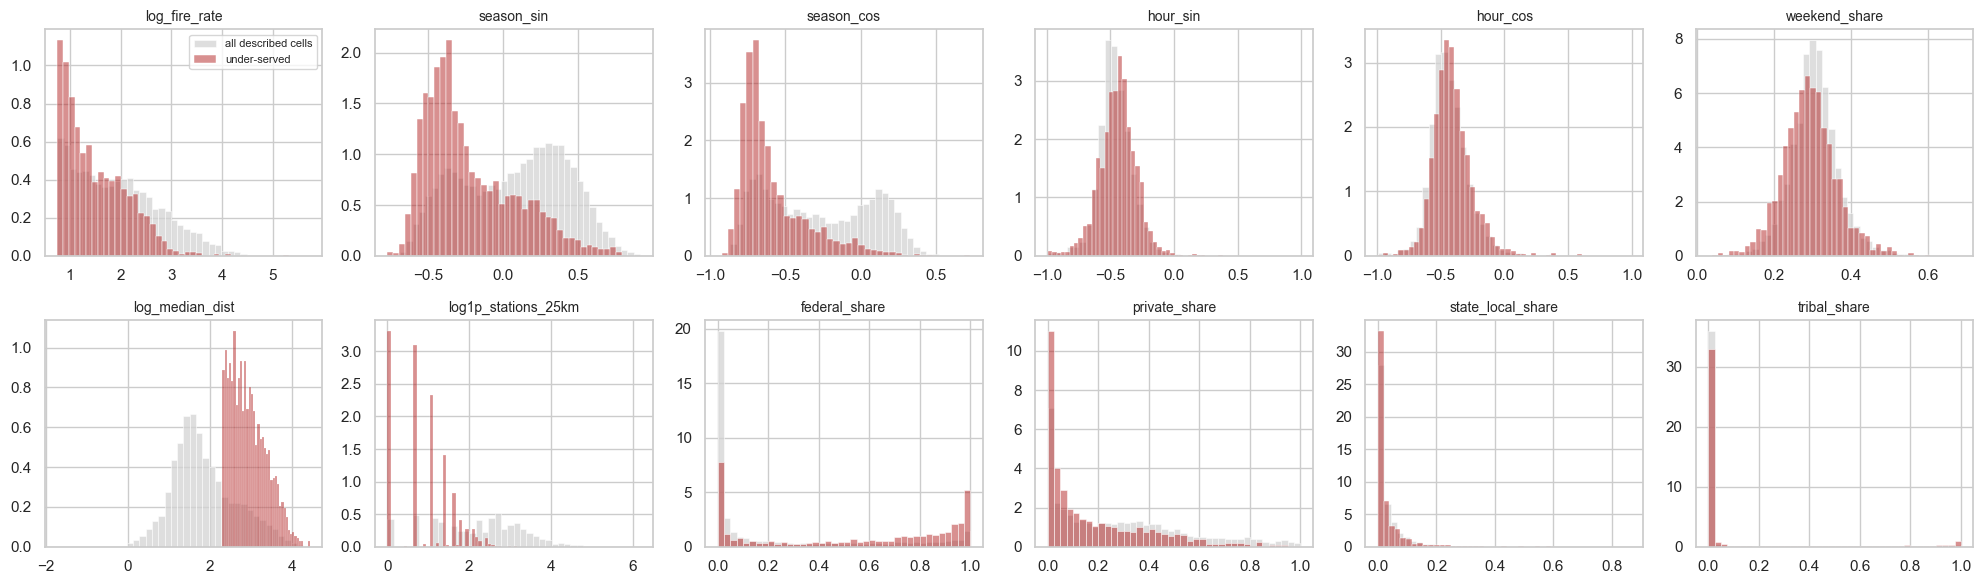

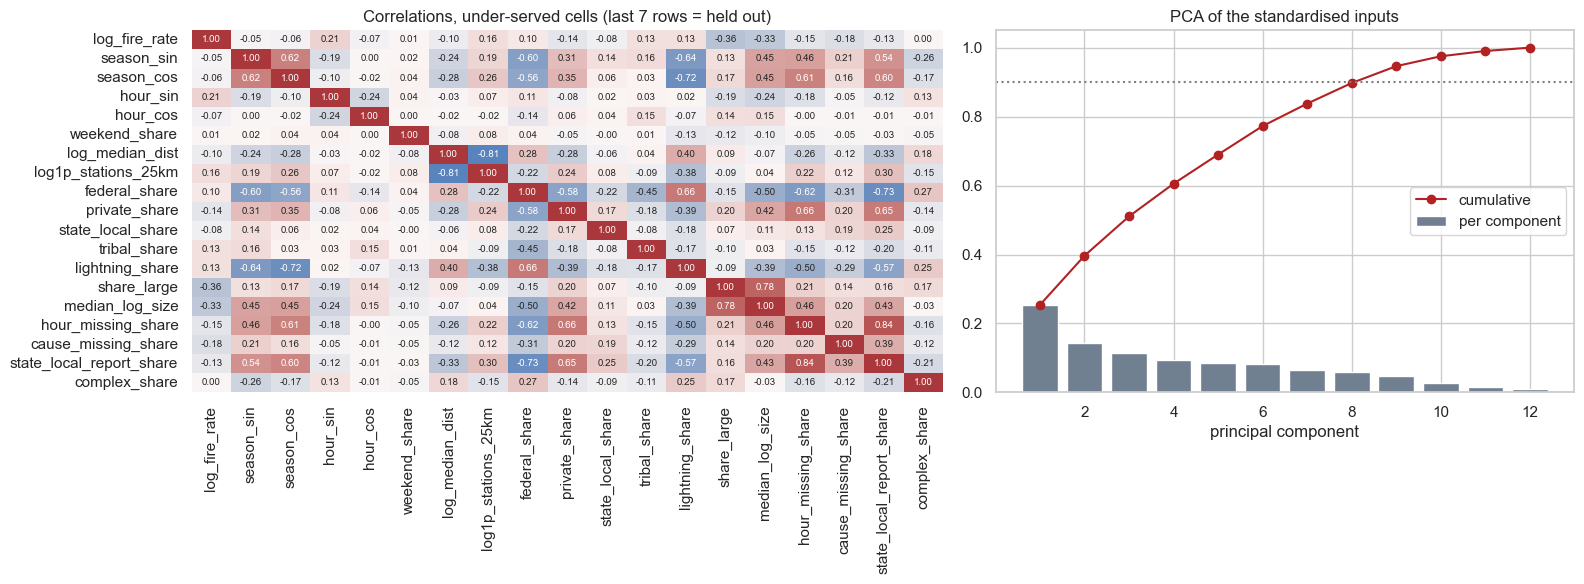

components for 90% of the variance: 9 of 12


In [6]:
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for ax, feat in zip(axes.flat, FEATURES):
    sns.histplot(described[feat].dropna(), ax=ax, color='lightgray', stat='density', bins=40, label='all described cells')
    sns.histplot(under[feat], ax=ax, color='firebrick', stat='density', bins=40, alpha=0.5, label='under-served')
    ax.set_title(feat, fontsize=10)
    ax.set_xlabel(''), ax.set_ylabel('')
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
savefig('feature_distributions.png')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(under[FEATURES + HELD_OUT].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, cbar=False,
            annot_kws={'size': 7}, ax=axes[0])
axes[0].set_title('Correlations, under-served cells (last 7 rows = held out)')
pca = PCA(random_state=SEED).fit(X)
axes[1].bar(range(1, len(FEATURES) + 1), pca.explained_variance_ratio_, color='slategray', label='per component')
axes[1].plot(range(1, len(FEATURES) + 1), np.cumsum(pca.explained_variance_ratio_), 'o-', color='firebrick',
             label='cumulative')
axes[1].axhline(0.9, color='gray', ls=':')
axes[1].set_xlabel('principal component')
axes[1].set_title('PCA of the standardised inputs')
axes[1].legend()
plt.tight_layout()
savefig('feature_corr_pca.png')
plt.show()
N_PC90 = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.9) + 1)
print(f'components for 90% of the variance: {N_PC90} of {len(FEATURES)}')

- Under-served cells differ from other cells mostly in **land owner** (much more federal land), **station access** (by construction) and **season** (summer-peaked). Weekend share and discovery hour look almost the same in both groups.
- The strongest input correlation is distance to the nearest station vs stations within 25 km (|r| = 0.81), as expected, since both measure access. Next come the season pair (0.62), season vs federal share (0.60) and federal vs private share (0.58). No other pair is close to duplicating another.
- PCA needs **9 of 12 components for 90 % of the variance**, so the inputs are not redundant. Section 4 still checks that clustering on the components gives the same answer.
- Among the held-out variables, lightning share and discovery-time missingness are clearly related to the inputs (federal share and season), which is what the held-out checks below rely on.

### 2.3 Is there any cluster structure to find?

The Hopkins statistic compares nearest-neighbour distances of real cells with those of uniform random points in the same box: about 0.5 means no more clustered than noise, close to 1 means strong structure.

In [7]:
hopkins_draws = np.array([hopkins(X, seed=SEED + i) for i in range(10)])
print(f'Hopkins statistic over 10 draws: mean {hopkins_draws.mean():.3f}, '
      f'range {hopkins_draws.min():.3f}-{hopkins_draws.max():.3f}')

Hopkins statistic over 10 draws: mean 0.832, range 0.821-0.841


- **Hopkins about 0.83** (range 0.82-0.84 over 10 draws), well above 0.5: the under-served cells are far from uniform in the feature space, so there is structure worth clustering.

## 3. Choosing the number of clusters

**Decision rule (fixed before looking at any cluster profile).** Internal indices reward compact, separated groups but say nothing about whether the same groups come back when the data change. Following Ben-Hur et al. (2002), we draw pairs of bootstrap resamples, fit K-Means to each, label all cells with both fits and compute the adjusted Rand index (ARI) between the two labelings. **We choose the largest k for which at least 90 % of the pairs agree with ARI > 0.8**, i.e. the most detailed partition that is still reproducible. The elbow, silhouette, Davies-Bouldin, Calinski-Harabasz and gap statistic are reported alongside it.

In [8]:
sweep = kmeans_sweep(X, K_RANGE, SEED)
stability = {k: bootstrap_stability(X, k, N_BOOT, SEED) for k in K_RANGE}
sweep['stability_mean'] = [stability[k].mean() for k in K_RANGE]
sweep['stability_p10'] = [np.quantile(stability[k], 0.1) for k in K_RANGE]
sweep['share_pairs_ari_gt_0.8'] = [(stability[k] > 0.8).mean() for k in K_RANGE]
gap = gap_statistic(X, K_RANGE, n_ref=10, seed=SEED)
sweep = sweep.join(gap)

STABLE_SHARE, STABLE_ARI = 0.9, 0.8
stable_ks = [k for k in K_RANGE if (stability[k] > STABLE_ARI).mean() >= STABLE_SHARE]
K = max(stable_ks)
gap_ok = [k for k in list(K_RANGE)[:-1] if gap.loc[k, 'gap'] >= gap.loc[k + 1, 'gap'] - gap.loc[k + 1, 'sk']]
display(sweep.round(3))
print(f'k passing the stability rule: {stable_ks} -> K = {K}')
print(f"best silhouette k = {sweep['silhouette'].idxmax()}, best Davies-Bouldin k = {sweep['davies_bouldin'].idxmin()}, "
      f"best Calinski-Harabasz k = {sweep['calinski_harabasz'].idxmax()}, "
      f"gap rule (Tibshirani) k = {gap_ok[0] if gap_ok else 'none in range'}")

C:\Users\jackd\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\jackd\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\jackd\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\jackd\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1039

,inertia,silhouette,davies_bouldin,calinski_harabasz,stability_mean,stability_p10,share_pairs_ari_gt_0.8,gap,sk
k,,,,,,,,,
2,19828.222,0.215,2.032,443.239,0.921,0.891,1.00,1.475,0.008
3,17524.472,0.247,1.703,382.943,0.852,0.350,0.88,1.497,0.006
4,15550.259,0.172,1.743,372.709,0.884,0.805,0.92,1.543,0.010
5,14450.513,0.174,1.843,338.920,0.787,0.651,0.52,1.562,0.006
6,13465.485,0.174,1.700,320.231,0.845,0.768,0.82,1.584,0.006
7,12828.316,0.151,1.758,296.605,0.764,0.549,0.56,1.601,0.007
8,12372.275,0.153,1.747,274.046,0.661,0.535,0.10,1.605,0.007
9,11936.029,0.142,1.741,257.600,0.629,0.521,0.04,1.614,0.009
10,11570.421,0.140,1.705,243.138,0.631,0.532,0.00,1.626,0.008


k passing the stability rule: [2, 4] -> K = 4
best silhouette k = 3, best Davies-Bouldin k = 6, best Calinski-Harabasz k = 2, gap rule (Tibshirani) k = 7


- **The internal indices disagree.** Silhouette is best at k = 3 (0.247), Calinski-Harabasz at k = 2, Davies-Bouldin is nearly flat (1.70 at k = 3, 6 and 10), the elbow has no sharp bend and the gap statistic keeps rising until k = 7. This is the usual sign of overlapping groups rather than well-separated blobs.
- **Stability breaks the tie.** k = 3 has the best silhouette but is not reproducible: in 12 % of bootstrap pairs the two fits disagree badly (ARI about 0.3, the outliers in the right panel), because the three-way split can fall in two different places. **k = 4 is the largest k with at least 90 % of pairs above ARI 0.8** (92 %, median ARI 0.89). From k = 5 on, agreement drops quickly (52 % at k = 5, 10 % at k = 8).
- **Chosen: k = 4.** The cost is a lower silhouette (0.17 vs 0.25), so these types should be read as overlapping regimes with clear cores, not as cleanly separated islands. Section 5 reports the silhouette of each type.

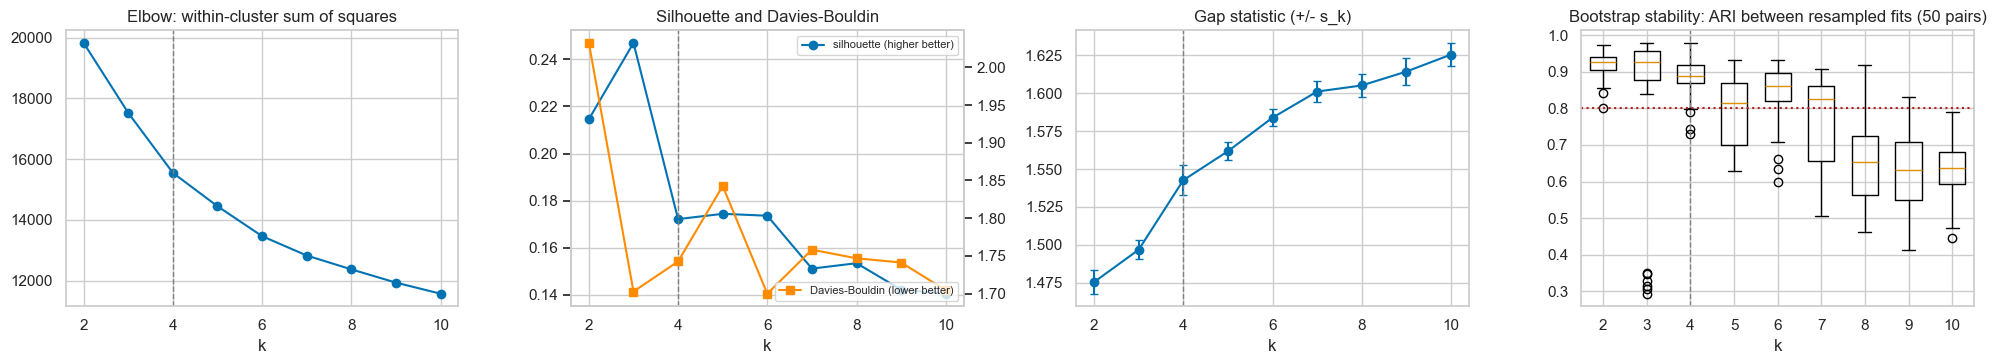

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
sweep['inertia'].plot(ax=axes[0], marker='o', title='Elbow: within-cluster sum of squares')
sweep['silhouette'].plot(ax=axes[1], marker='o', label='silhouette (higher better)')
ax2 = axes[1].twinx()
sweep['davies_bouldin'].plot(ax=ax2, marker='s', color='darkorange', label='Davies-Bouldin (lower better)')
axes[1].set_title('Silhouette and Davies-Bouldin')
axes[1].legend(loc='upper right', fontsize=8), ax2.legend(loc='lower right', fontsize=8)
ax2.grid(False)
axes[2].errorbar(gap.index, gap['gap'], yerr=gap['sk'], marker='o', capsize=3)
axes[2].set_title('Gap statistic (+/- s_k)')
axes[3].boxplot([stability[k] for k in K_RANGE], positions=list(K_RANGE), widths=0.6)
axes[3].axhline(STABLE_ARI, color='firebrick', ls=':')
axes[3].set_title(f'Bootstrap stability: ARI between resampled fits ({N_BOOT} pairs)')
for ax in axes:
    ax.set_xlabel('k')
    ax.axvline(K, color='gray', ls='--', lw=1)
plt.tight_layout()
savefig('model_selection.png')
plt.show()

## 4. Comparing algorithm families

The same standardised cells go to four families. Agreement with K-Means is measured with the ARI.

- **Gaussian mixture** (model-based, soft): BIC over k and two covariance types.
- **Ward agglomerative** (hierarchical, same variance criterion as K-Means but greedy).
- **K-Means on the first principal components** covering 90 % of the variance (checks that correlated inputs are not double-counted).
- **HDBSCAN** (density-based): a sweep over `min_cluster_size`, in the full space and in the first three principal components.

In [10]:
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
labels = km.labels_

bic = pd.DataFrame({cov: {k: GaussianMixture(k, covariance_type=cov, n_init=3, random_state=SEED).fit(X).bic(X)
                          for k in K_RANGE} for cov in ('full', 'diag')})
gmm = GaussianMixture(K, covariance_type='full', n_init=5, random_state=SEED).fit(X)
ward = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X)
Z90 = PCA(N_PC90, random_state=SEED).fit_transform(X)
pca_km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(Z90)

hdb_rows = []
for space, data in [('all inputs', X), ('first 3 PCs', Z90[:, :3])]:
    for mcs in (10, 15, 25, 50, 100):
        lab = HDBSCAN(min_cluster_size=mcs).fit_predict(data)
        hdb_rows.append({'space': space, 'min_cluster_size': mcs, 'clusters': lab.max() + 1, 'noise': (lab < 0).mean()})
hdb = pd.DataFrame(hdb_rows)

agreement = pd.Series({'Gaussian mixture (full, same k)': adjusted_rand_score(labels, gmm.predict(X)),
                       'Ward agglomerative': adjusted_rand_score(labels, ward),
                       f'K-Means on {N_PC90} PCs (90% variance)': adjusted_rand_score(labels, pca_km)},
                      name=f'ARI vs K-Means (k={K})')
display(bic.round(0).T)
print('BIC minimum:', {cov: int(bic[cov].idxmin()) for cov in bic})
display(agreement.round(3).to_frame())
display(hdb.style.format({'noise': '{:.0%}'}))

,2,3,4,5,6,7,8,9,10
full,42217.0,34321.0,32906.0,29694.0,28380.0,26396.0,26736.0,24833.0,23945.0
diag,48089.0,39851.0,34932.0,33971.0,29965.0,29222.0,27891.0,24881.0,24791.0


BIC minimum: {'full': 10, 'diag': 10}


,ARI vs K-Means (k=4)
"Gaussian mixture (full, same k)",0.192
Ward agglomerative,0.563
K-Means on 9 PCs (90% variance),0.975


,space,min_cluster_size,clusters,noise
0,all inputs,10,2,37%
1,all inputs,15,2,40%
2,all inputs,25,0,100%
3,all inputs,50,0,100%
4,all inputs,100,0,100%
5,first 3 PCs,10,2,13%
6,first 3 PCs,15,2,15%
7,first 3 PCs,25,2,16%
8,first 3 PCs,50,2,85%
9,first 3 PCs,100,0,100%


- **K-Means on 9 principal components** gives almost the same partition (ARI 0.975), so the result does not depend on correlated inputs being counted twice.
- **Ward agglomerative** agrees moderately (ARI 0.56). It optimises the same variance criterion greedily, so the cores match but borderline cells move.
- **The Gaussian mixture does not help here.** Its BIC keeps falling up to k = 10 for both covariance types, and at k = 4 it agrees poorly with K-Means (ARI 0.19). The owner shares pile up at exactly 0 and 1, and a full-covariance mixture spends components on those point masses instead of on fire regimes. BIC is therefore not a usable guide for k on this data.
- **HDBSCAN finds no density-separated groups.** In the full space it labels 37-100 % of cells as noise; in the first 3 PCs it finds only 2 clusters, and with larger minimum sizes everything becomes noise. The cells form a continuum with dense cores, which is why a partitioning method plus a stability check fits better than a density method.

## 5. The cell types

In [11]:
sil = silhouette_samples(X, labels)
under['cluster'] = labels
under['silhouette'] = sil


def name_types(centres: pd.DataFrame) -> dict:
    """Name clusters from their centres (standardised units), so names follow the data, not the label numbers."""
    if len(centres) != 4:
        return {c: f'Type {c}' for c in centres.index}
    names, left = {}, list(centres.index)
    for feature, name in [('tribal_share', 'Tribal lands'), ('private_share', 'Private-land spring fires'),
                          ('log_median_dist', 'Remote federal wildlands')]:
        pick = centres.loc[left, feature].idxmax()
        names[pick] = name
        left.remove(pick)
    names[left[0]] = 'Federal forests, partial coverage'
    return names


centres = pd.DataFrame(km.cluster_centers_, columns=FEATURES)
TYPE_NAMES = name_types(centres)
under['type'] = under['cluster'].map(TYPE_NAMES)
TYPE_ORDER = [TYPE_NAMES[c] for c in sorted(TYPE_NAMES)]

profile = under.groupby('type').agg(cells=('n_fires', 'size'), fires_per_cell=('n_fires', 'mean'),
                                    silhouette=('silhouette', 'mean'),
                                    **{f: (f, 'mean') for f in FEATURES}).loc[TYPE_ORDER]
profile['median_km_to_station'] = np.exp(profile.pop('log_median_dist'))
profile['peak_day_of_year'] = (np.degrees(np.arctan2(profile['season_sin'], profile['season_cos'])) % 360) / 360 * 365.25
profile['season_concentration'] = np.hypot(profile['season_sin'], profile['season_cos'])
profile['peak_hour'] = (np.degrees(np.arctan2(profile['hour_sin'], profile['hour_cos'])) % 360) / 15 - 0.5
display(profile.drop(columns=['season_sin', 'season_cos', 'hour_sin', 'hour_cos']).round(2).T)

type,Private-land spring fires,"Federal forests, partial coverage",Remote federal wildlands,Tribal lands
cells,414.00,788.00,617.00,197.00
fires_per_cell,96.15,140.33,101.72,196.31
silhouette,0.09,0.17,0.20,0.27
log_fire_rate,1.33,1.63,1.37,1.71
weekend_share,0.29,0.30,0.29,0.29
log1p_stations_25km,1.24,1.30,0.20,0.68
federal_share,0.09,0.69,0.83,0.05
private_share,0.44,0.17,0.10,0.07
state_local_share,0.06,0.03,0.02,0.01
tribal_share,0.02,0.02,0.01,0.83


| Type | Cells | Fires look like | Station access | Silhouette |
|---|---|---|---|---|
| **Private-land spring fires** | 414 | 44 % private land; broad season peaking around day 150 (late May), the least concentrated season of the four | median 14.9 km, about 2.5 stations within 25 km | 0.09 |
| **Federal forests, partial coverage** | 788 | 69 % federal; tight summer peak (late July); highest fire rate after tribal lands | median 14.5 km, about 2.7 stations | 0.17 |
| **Remote federal wildlands** | 617 | 83 % federal; tight summer peak | **median 30.4 km, usually no station within 25 km** | 0.20 |
| **Tribal lands** | 197 | 83 % tribal or BIA trust land; summer peak; the busiest cells (196 fires per cell) | median 20.4 km | 0.27 |

- The types are separated mainly by **who owns the land**, **when fires happen** and **how far the stations are**. Weekend share and discovery hour barely differ between them.
- Private-land spring fires has the lowest silhouette (0.09). It is the most mixed type, a catch-all for non-federal under-served land from Texas to Florida and Minnesota.

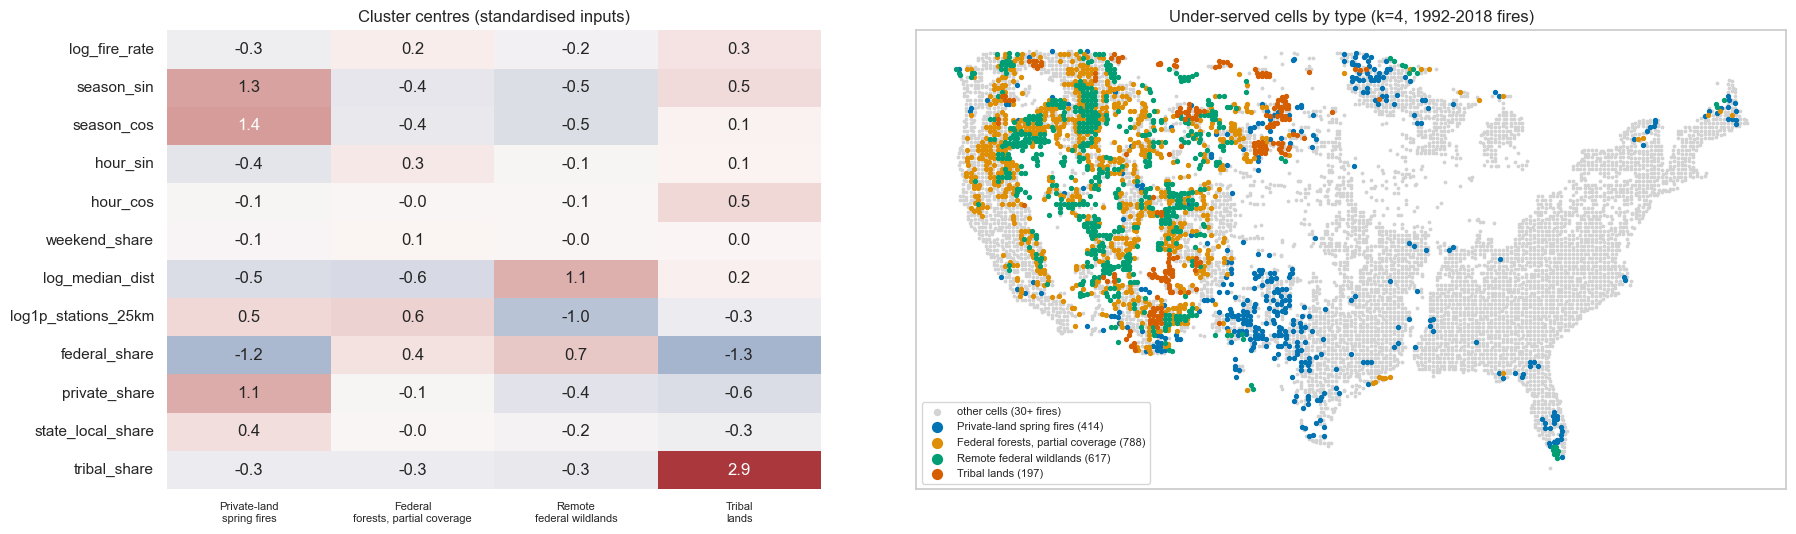

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5), gridspec_kw={'width_ratios': [1, 1.6]})
c_named = centres.rename(index=TYPE_NAMES).loc[TYPE_ORDER]
sns.heatmap(c_named.T, annot=True, fmt='.1f', cmap='vlag', center=0, ax=axes[0], cbar=False)
axes[0].set_title('Cluster centres (standardised inputs)')
axes[0].set_xticklabels([t.replace(' ', '\n', 1) for t in TYPE_ORDER], rotation=0, fontsize=8)
axes[1].scatter(described['lon'], described['lat'], s=3, color='lightgray', label='other cells (30+ fires)')
for t in TYPE_ORDER:
    s = under[under['type'] == t]
    axes[1].scatter(s['lon'], s['lat'], s=8, label=f'{t} ({len(s)})')
axes[1].set_title(f'Under-served cells by type (k={K}, 1992-2018 fires)')
axes[1].set_xticks([]), axes[1].set_yticks([])
axes[1].set_aspect(1.25)
axes[1].legend(markerscale=2.5, fontsize=8, loc='lower left')
plt.tight_layout()
savefig('cluster_profile_map.png')
plt.show()

- The map shows that the types are **spatially coherent even though coordinates were never an input**:
  - Remote federal wildlands fill the Great Basin, central Idaho, Wyoming and the Arizona-New Mexico border.
  - Federal forests with partial coverage line the Cascades, the Sierra Nevada and the northern and central Rockies.
  - Tribal lands sit on the large reservations of the Southwest and the northern Plains.
  - Private-land spring fires are concentrated in central and south Texas and Oklahoma, Florida and northern Minnesota.

## 6. Do the types mean something? Held-out checks

None of these variables was an input. If the types only reflected noise in the inputs, the held-out variables would not differ between them. Effect sizes: $\eta^2$ (share of the cell-level variance explained by type) for numeric variables and Cramér's V for region.

We also look at two kinds of operational reality named in the spec: **fire complexes** (fires grouped under one `COMPLEX_NAME`, usually lightning busts) and **historical anomalies** (the 100 largest 1992-2018 fires in the lower 48). For that table every fire is placed in its cell's class: one of the four types, a *served cell* (30+ fires, median fire under 10 km from a station) or a *sparse cell* (fewer than 30 fires in 1992-2018).

In [13]:
heldout = under.groupby('type')[HELD_OUT].mean().loc[TYPE_ORDER]
effect = pd.Series({v: eta_squared(under[v], under['type']) for v in HELD_OUT}, name='eta squared')
effect['region (Cramer V)'] = cramers_v(under['type'], under['region'])
display(heldout.round(3).T)
display(effect.round(3).to_frame())

OTHER_CLASSES = ['served cell', 'sparse cell']
cell_class = pd.Series(np.where(cells['n_fires'] >= MIN_FIRES, 'served cell', 'sparse cell'), index=cells.index)
cell_class.loc[under.index] = under['type']


def type_of(frame: pd.DataFrame) -> pd.Series:
    # class of each fire's grid cell (built from 1992-2018): an under-served type, a served cell
    # (30+ fires, median fire < 10 km from a station) or a sparse cell (< 30 fires, or no fire before 2019)
    keys = pd.MultiIndex.from_frame(frame[['CY', 'CX']])
    return pd.Series(cell_class.reindex(keys).to_numpy(), index=frame.index).fillna('sparse cell')


hist_type = type_of(hist)
top = hist['FIRE_SIZE'].nlargest(100).index
anomaly = pd.DataFrame({'share of all fires': hist_type.value_counts(normalize=True),
                        'share of acres': hist.groupby(hist_type)['FIRE_SIZE'].sum() / hist['FIRE_SIZE'].sum(),
                        'share of 100 largest fires': hist_type.loc[top].value_counts(normalize=True),
                        'share of complex fires': hist_type[hist['IN_COMPLEX']].value_counts(normalize=True)}
                       ).fillna(0).loc[TYPE_ORDER + OTHER_CLASSES]
display(anomaly.style.format('{:.1%}'))

type,Private-land spring fires,"Federal forests, partial coverage",Remote federal wildlands,Tribal lands
lightning_share,0.187,0.595,0.756,0.385
share_large,0.131,0.066,0.094,0.057
median_log_size,0.390,-0.604,-0.527,-0.262
hour_missing_share,0.556,0.091,0.039,0.053
cause_missing_share,0.080,0.035,0.020,0.012
state_local_report_share,0.826,0.206,0.083,0.079
complex_share,0.004,0.013,0.023,0.004


,eta squared
lightning_share,0.458
share_large,0.066
median_log_size,0.247
hour_missing_share,0.528
cause_missing_share,0.080
state_local_report_share,0.604
complex_share,0.060
region (Cramer V),0.432


,share of all fires,share of acres,share of 100 largest fires,share of complex fires
Private-land spring fires,1.9%,6.1%,7.0%,2.4%
"Federal forests, partial coverage",5.2%,14.4%,12.0%,25.6%
Remote federal wildlands,3.0%,15.5%,21.0%,23.4%
Tribal lands,1.8%,2.1%,1.0%,2.1%
served cell,85.4%,42.4%,33.0%,40.3%
sparse cell,2.7%,19.5%,26.0%,6.2%


- **Held-out cause separates the types strongly** (η² = 0.46): lightning causes 76 % of fires in remote federal wildlands and 60 % in federal forests, but only 19 % in private-land spring fires. Cause was never an input.
- **Administrative reporting patterns are the strongest signal of all.** Whether a state or local agency filed the report (η² = 0.60) and whether the discovery time is missing (η² = 0.53) differ sharply: 83 % of private-land fires are reported by state or local agencies and 56 % have no discovery time, against 4-9 % missing times for the three federal and tribal types. Without using any agency label, the clustering has recovered the federal / non-federal reporting divide that Milestone 1 found in the missing values.
- **Region**, also held out, lines up with the types (Cramér's V = 0.43): remote wildlands are 61 % Mountain West, private-land spring fires 42 % Plains, tribal lands split between the Plains and the Southwest.
- **Fire size differs less** (η² = 0.07 for the large-fire share, 0.25 for median size). Private-land spring fires have the highest large-fire share (13 %) despite being only 15 km from a station: grass and range fires spread fast.
- **Fire complexes concentrate in the federal types.** Federal forests and remote wildlands together hold 49 % of all complex fires (multi-fire lightning events) but only 8.2 % of fires.
- **Historical anomalies:** the two federal types hold 8.2 % of fires but 30 % of the acres and 33 of the 100 largest fires. **Sparse cells** (fewer than 30 fires in 27 years, so too few to be clustered) hold only 2.7 % of fires but 19.5 % of the acres and **26 of the 100 largest fires**. The places with almost no fire history and no station are where the biggest fires happen, and they are outside the typology by design (see the summary).

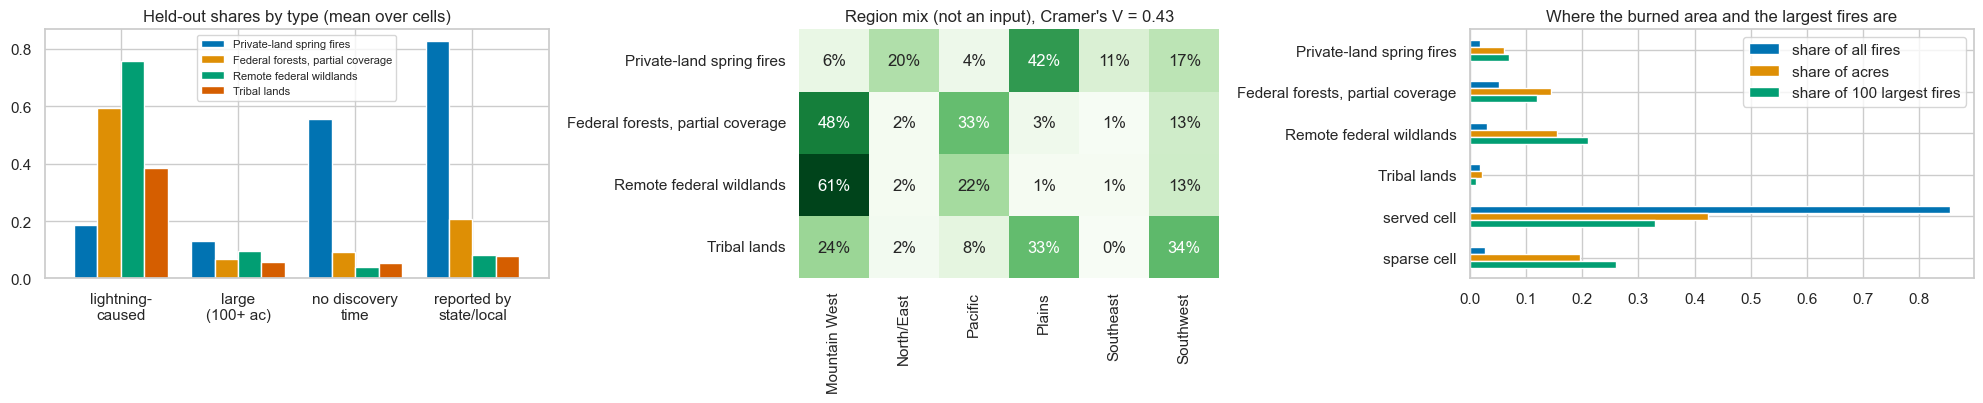

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.2), gridspec_kw={'width_ratios': [1.2, 1, 1.2]})
show = heldout[['lightning_share', 'share_large', 'hour_missing_share', 'state_local_report_share']]
show.columns = ['lightning-\ncaused', 'large\n(100+ ac)', 'no discovery\ntime', 'reported by\nstate/local']
show.T.plot.bar(ax=axes[0], rot=0, width=0.8)
axes[0].set_title('Held-out shares by type (mean over cells)')
axes[0].legend(fontsize=8)
sns.heatmap(pd.crosstab(under['type'], under['region'], normalize='index').loc[TYPE_ORDER], annot=True, fmt='.0%',
            cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title(f"Region mix (not an input), Cramer's V = {effect['region (Cramer V)']:.2f}")
axes[1].set_ylabel('')
anomaly[['share of all fires', 'share of acres', 'share of 100 largest fires']].plot.barh(ax=axes[2])
axes[2].set_title('Where the burned area and the largest fires are')
axes[2].invert_yaxis()
for ax in axes[1:]:
    ax.set_xlabel('')
plt.tight_layout()
savefig('heldout_validation.png')
plt.show()

## 7. Do the types hold up in 2019-2024?

The clusters were built from 1992-2018 only. For every under-served cell with at least 10 fires in 2019-2024 we recompute the inputs from the new fires alone, standardise them with the **1992-2018 scaler** and assign each cell to the nearest 1992-2018 centre. Agreement with its original type is measured with Cohen's $\kappa$ (0 = chance, 1 = identical). We also check whether the held-out large-fire rate still differs by type in the new years.

In [15]:
MIN_FIRES_LATER = 10
later = fires[fires['FIRE_YEAR'] >= SPLIT_YEAR]
later_cells = cell_features(later, later['FIRE_YEAR'].nunique())
later_cells = later_cells[later_cells['n_fires'] >= MIN_FIRES_LATER].join(under[['type']], how='inner')
later_cells[['hour_sin', 'hour_cos']] = later_cells[['hour_sin', 'hour_cos']].fillna(hour_fill)
later_cells['type_2019'] = pd.Series(km.predict(scaler.transform(later_cells[FEATURES])),
                                     index=later_cells.index).map(TYPE_NAMES)
kappa = cohen_kappa_score(later_cells['type'], later_cells['type_2019'])
kept = (later_cells['type'] == later_cells['type_2019']).mean()
print(f'{len(later_cells):,} of {len(under):,} under-served cells have {MIN_FIRES_LATER}+ fires in 2019-2024; '
      f'{kept:.1%} keep their type, Cohen kappa = {kappa:.2f}')
transition = pd.crosstab(later_cells['type'], later_cells['type_2019'], normalize='index').reindex(
    index=TYPE_ORDER, columns=TYPE_ORDER, fill_value=0)
display(transition.style.format('{:.0%}'))

later_type = type_of(later)
in_type = later_type.isin(TYPE_ORDER)
outcome = later[in_type].groupby(later_type[in_type])['LARGE'].agg(fires='size', large='sum').loc[TYPE_ORDER]
outcome['share_large'] = outcome['large'] / outcome['fires']
outcome['lo'], outcome['hi'] = wilson_bounds(outcome['large'], outcome['fires'], 1.96)
outcome['share_large_1992_2018'] = hist.groupby(hist_type)['LARGE'].mean().loc[TYPE_ORDER]
display(outcome.style.format({'fires': '{:,}', 'large': '{:,}', 'share_large': '{:.2%}', 'lo': '{:.2%}',
                              'hi': '{:.2%}', 'share_large_1992_2018': '{:.2%}'}))

1,288 of 2,016 under-served cells have 10+ fires in 2019-2024; 84.7% keep their type, Cohen kappa = 0.78


type_2019,Private-land spring fires,"Federal forests, partial coverage",Remote federal wildlands,Tribal lands
type,,,,
Private-land spring fires,92%,5%,1%,1%
"Federal forests, partial coverage",15%,81%,4%,1%
Remote federal wildlands,4%,12%,84%,0%
Tribal lands,5%,1%,2%,91%


,fires,large,share_large,lo,hi,share_large_1992_2018
Private-land spring fires,"6,648",573,8.62%,7.97%,9.32%,9.94%
"Federal forests, partial coverage","18,579",909,4.89%,4.59%,5.21%,4.49%
Remote federal wildlands,"8,745",805,9.21%,8.62%,9.83%,6.73%
Tribal lands,"5,815",281,4.83%,4.31%,5.41%,3.29%


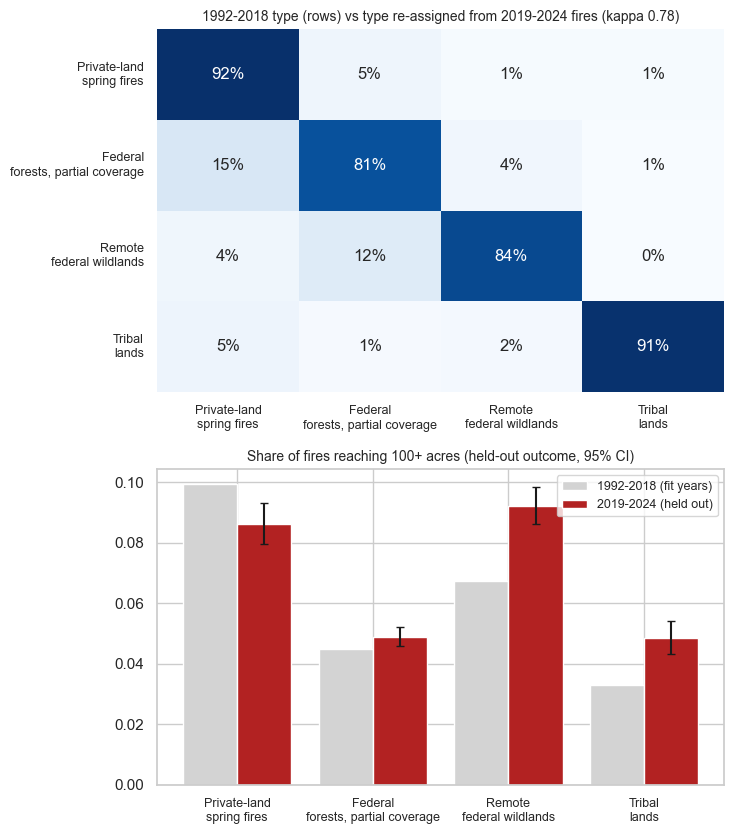

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(7.5, 8.5), gridspec_kw={'height_ratios': [1.15, 1]})  # one report column
wrapped = [t.replace(' ', '\n', 1) for t in TYPE_ORDER]
sns.heatmap(transition, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title(f'1992-2018 type (rows) vs type re-assigned from 2019-2024 fires (kappa {kappa:.2f})', fontsize=10)
axes[0].set_xlabel(''), axes[0].set_ylabel('')
axes[0].set_xticklabels(wrapped, rotation=0, fontsize=9)
axes[0].set_yticklabels(wrapped, rotation=0, fontsize=9)
x = np.arange(len(outcome))
axes[1].bar(x - 0.2, outcome['share_large_1992_2018'], width=0.4, color='lightgray', label='1992-2018 (fit years)')
axes[1].bar(x + 0.2, outcome['share_large'], width=0.4, color='firebrick', label='2019-2024 (held out)',
            yerr=[outcome['share_large'] - outcome['lo'], outcome['hi'] - outcome['share_large']], capsize=3)
axes[1].set_xticks(x, wrapped, fontsize=9)
axes[1].set_title('Share of fires reaching 100+ acres (held-out outcome, 95% CI)', fontsize=10)
axes[1].legend(fontsize=9)
plt.tight_layout()
savefig('temporal_validation.png')
plt.show()

- **The types persist.** 1,288 under-served cells have 10+ fires in 2019-2024. Rebuilt from the new fires alone and assigned to the 1992-2018 centres, **84.7 % keep their type (Cohen's κ = 0.78)**. Tribal lands (91 %) and private-land spring fires (92 %) are the most stable. Federal forests lose 15 % to the private type, partly because the 2020-21 reporting changes (Milestone 1) affect owner coding.
- **The held-out large-fire rate still differs by type in the new years**, but the order changed. Remote federal wildlands rose from 6.7 % to **9.2 %** (95 % CI 8.6-9.8 %) and are now the highest, while private-land spring fires fell from 9.9 % to 8.6 %. Federal forests and tribal lands stay lowest at about 4.9 %.

## 8. What drives the types? Feature-group ablation

Drop one group of inputs, refit K-Means with the same k and compare with the full solution. A low ARI means that group shapes the partition.

In [17]:
GROUPS = {'land owner shares': ['federal_share', 'private_share', 'state_local_share', 'tribal_share'],
          'season (sin, cos)': ['season_sin', 'season_cos'],
          'station access (distance, count)': ['log_median_dist', 'log1p_stations_25km'],
          'discovery hour (sin, cos)': ['hour_sin', 'hour_cos'],
          'fire rate': ['log_fire_rate'],
          'weekend share': ['weekend_share']}
ablation = pd.Series({name: adjusted_rand_score(labels, KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(
    X[:, [i for i, f in enumerate(FEATURES) if f not in drop]])) for name, drop in GROUPS.items()},
    name='ARI vs full solution').sort_values()
display(ablation.round(3).to_frame())

,ARI vs full solution
"station access (distance, count)",0.381
land owner shares,0.413
"season (sin, cos)",0.624
fire rate,0.866
"discovery hour (sin, cos)",0.874
weekend share,0.973


- **Station access (ARI 0.38) and land owner (0.41) shape the partition most**, then season (0.62). Fire rate (0.87), discovery hour (0.87) and weekend share (0.97) hardly matter.
- This differs from the Milestone 1 preliminary clustering, where distance mattered little. That version included fire-size features, which this version moves to the held-out side to avoid circularity with RQ1. Without them, how far help is becomes one of the two main axes.
- Discovery hour and weekend share could be dropped with little change. We keep them because the ablation shows they do no harm, and the hour pair is the cyclical encoding of `DISCOVERY_TIME`.

## 9. Association rules: which conditions go with large fires?

Clusters describe places; rules describe individual fires. Each 1992-2018 lower-48 fire is a transaction with exactly one item per attribute, and every rule has the consequent `LARGE` (100+ acres):

| Attribute | Items |
|---|---|
| region | 6 lower-48 regions |
| season | winter / spring / summer / autumn (from day of year) |
| owner | the 5 land-owner groups |
| distance | < 5, 5-10, 10-20, 20+ km to the nearest station |
| cause | Human / Natural / Missing |
| time | day (08-19 h) / night / unknown |
| weekend | yes / no |
| cell type | the under-served type of the fire's cell, *served cell* or *sparse cell* (< 30 fires in 1992-2018) |

Because each transaction has one item per attribute, enumerating all attribute combinations of length 1-3 with a group-by returns exactly the frequent itemsets Apriori would find, with exact counts.

**Thresholds and why.** Let $p_0$ be the 1992-2018 large-fire rate.
1. *Minimum support.* A rule's confidence is a proportion estimated from its $n$ matching fires. We want its 95 % interval to be no wider than $\pm 25\%$ of $p_0$ even for a rule with lift near 1: $1.96\sqrt{p_0(1-p_0)/n} \le 0.25\,p_0$, so $n \ge 1.96^2(1-p_0)/(0.25^2 p_0)$.
2. *Minimum confidence / lift.* With $m$ candidate rules tested, a rule is kept only if the one-sided Bonferroni-corrected Wilson lower bound of its confidence is at least $2p_0$, i.e. we are 95 % confident (family-wise) that matching fires are **at least twice** as likely to become large as an average fire.
3. *Non-redundancy.* A longer rule is kept only if that same lower bound beats the point confidence of every one of its sub-rules (minimum improvement, Bayardo et al. 2000).

The thresholds are then checked against the 2019-2024 fires, which they never saw, and a sensitivity grid shows how the replication rate moves when they are relaxed.

In [18]:
def season_of(doy_sin, doy_cos):
    doy = (np.arctan2(doy_sin, doy_cos) % (2 * np.pi)) / (2 * np.pi) * 365.25
    return np.select([(doy >= 60) & (doy < 152), (doy >= 152) & (doy < 244), (doy >= 244) & (doy < 335)],
                     ['spring', 'summer', 'autumn'], 'winter')


items = pd.DataFrame({
    'region': fires['REGION'].astype(str),
    'season': season_of(fires['DOY_SIN'], fires['DOY_COS']),
    'owner': fires['OWNER_GRP'],
    'distance': pd.cut(fires['D1_KM'], [-np.inf, 5, 10, 20, np.inf], right=False,
                       labels=['<5km', '5-10km', '10-20km', '20+km']).astype(str),
    'cause': fires['CAUSE'].astype(str),
    'time': np.select([fires['DISC_HOUR'].between(8, 19), fires['DISC_HOUR'].notna()], ['day', 'night'], 'unknown'),
    'weekend': np.where(fires['WEEKEND'], 'yes', 'no'),
    'cell_type': type_of(fires),
})
is_hist = (fires['FIRE_YEAR'] < SPLIT_YEAR).to_numpy()
y_hist, y_later = fires.loc[is_hist, 'LARGE'], fires.loc[~is_hist, 'LARGE']
P0, P0_LATER = y_hist.mean(), y_later.mean()
REL_PRECISION, MIN_LIFT, MAX_LEN = 0.25, 2.0, 3
PRECISION_GRID = (0.5, 0.25, 0.1)       # for the sensitivity check below
N_MIN = min_support_count(P0, REL_PRECISION)
print(f'large-fire rate 1992-2018 p0 = {P0:.3%} (2019-2024: {P0_LATER:.3%})')
print(f'minimum matches n_min = {N_MIN:,} fires = minimum support {N_MIN / len(y_hist):.4%}')

# mine once at the loosest support in the grid; each setting then filters and applies its own Bonferroni count
all_rules = mine_rules(items[is_hist].reset_index(drop=True), y_hist.reset_index(drop=True), MAX_LEN,
                       min_support_count(P0, max(PRECISION_GRID)))


def candidates(n_min: int) -> pd.DataFrame:
    base = all_rules[all_rules['matches'] >= n_min]
    return add_improvement(rule_significance(base, P0, n_tests=len(base)))


rules_hist = candidates(N_MIN)
N_TESTS = len(rules_hist)
print(f'{N_TESTS:,} candidate rules with at least n_min matches (Bonferroni over all of them)')

large-fire rate 1992-2018 p0 = 2.857% (2019-2024: 2.425%)
minimum matches n_min = 2,091 fires = minimum support 0.0986%


2,916 candidate rules with at least n_min matches (Bonferroni over all of them)


- The 1992-2018 large-fire rate is $p_0$ = 2.86 %. The precision target gives **$n_{\min}$ = 2,091 matching fires (minimum support 0.099 %)**, and 2,916 candidate rules meet it. The Bonferroni correction uses all of them, a one-sided z of 4.14.

In [19]:
later_items = items[~is_hist].reset_index(drop=True)
later_y = y_later.to_numpy()


def select_rules(rules: pd.DataFrame, min_lift: float) -> pd.DataFrame:
    strong = rules['lift_lower'] >= min_lift
    non_redundant = rules['best_subrule_conf'].isna() | (rules['conf_lower'] > rules['best_subrule_conf'])
    return rules[strong & non_redundant].sort_values('lift_lower', ascending=False)


def replicate(selected: pd.DataFrame) -> pd.DataFrame:
    # score the selected rules on 2019-2024 fires only
    rows = []
    for ante in selected['antecedent']:
        mask = np.ones(len(later_y), dtype=bool)
        for item in ante:
            attr, value = item.split('=', 1)
            mask &= later_items[attr].to_numpy() == value
        n, k = int(mask.sum()), int(later_y[mask].sum())
        rows.append({'antecedent': ante, 'matches_2019': n, 'large_2019': k,
                     'lift_2019': (k / n) / P0_LATER if n else np.nan})
    return pd.DataFrame(rows, columns=['antecedent', 'matches_2019', 'large_2019', 'lift_2019'])


selected = select_rules(rules_hist, MIN_LIFT)
selected = selected.merge(replicate(selected), on='antecedent')
print(f'{len(selected)} rules pass support, Bonferroni lift >= {MIN_LIFT} and non-redundancy')
print(f"2019-2024: {(selected['lift_2019'] > 1).mean():.0%} still have lift > 1, "
      f"{(selected['lift_2019'] >= MIN_LIFT).mean():.0%} still have lift >= {MIN_LIFT}, "
      f"Spearman rank correlation of lifts {selected[['lift', 'lift_2019']].corr('spearman').iat[0, 1]:.2f}")
show_rules = selected.assign(rule=selected['antecedent'].map(lambda a: ' & '.join(a)))
failed = show_rules[show_rules['lift_2019'] < MIN_LIFT]
print(f'{len(failed)} rules fall below lift {MIN_LIFT} on 2019-2024:')
print(failed[['rule', 'lift', 'lift_2019']].round(2).to_string(index=False))
display(show_rules[['rule', 'matches', 'support', 'confidence', 'lift', 'lift_lower', 'improvement', 'matches_2019',
                    'lift_2019']].head(20).style.format({'matches': '{:,}', 'support': '{:.3%}', 'confidence': '{:.1%}',
                                                         'lift': '{:.2f}', 'lift_lower': '{:.2f}',
                                                         'improvement': '{:+.3f}', 'matches_2019': '{:,}',
                                                         'lift_2019': '{:.2f}'}).hide(axis='index'))

121 rules pass support, Bonferroni lift >= 2.0 and non-redundancy
2019-2024: 98% still have lift > 1, 88% still have lift >= 2.0, Spearman rank correlation of lifts 0.66
14 rules fall below lift 2.0 on 2019-2024:
                                                                  rule  lift  lift_2019
                 season=summer & owner=private & cell_type=sparse cell  6.26       1.68
                                                 cell_type=sparse cell  4.58       1.43
                                  region=Southwest & owner=state_local  3.97       0.54
                                         region=Plains & cause=Missing  3.42       1.82
                            region=Plains & owner=private & time=night  3.61       1.59
                                       region=Southwest & time=unknown  3.20       1.28
                                     owner=state_local & cause=Missing  2.96       0.89
                  region=Mountain West & owner=missing & cause=Natural  2.93       

rule,matches,support,confidence,lift,lift_lower,improvement,matches_2019,lift_2019
region=Plains & distance=20+km & cell_type=sparse cell,"2,649",0.125%,28.1%,9.83,8.62,+0.079,773,10.72
owner=private & distance=20+km & cell_type=sparse cell,"3,452",0.163%,26.1%,9.15,8.11,+0.059,"1,832",7.27
owner=private & cause=Natural & cell_type=sparse cell,"3,290",0.155%,25.7%,8.98,7.92,+0.056,"2,415",3.89
region=Plains & time=day & cell_type=Private-land spring fires,"2,421",0.114%,25.6%,8.95,7.73,+0.109,784,9.05
region=Plains & cause=Natural & cell_type=sparse cell,"2,577",0.122%,25.3%,8.87,7.69,+0.053,665,7.07
region=Pacific & season=summer & cell_type=sparse cell,"2,699",0.127%,24.5%,8.56,7.42,+0.034,744,7.98
distance=20+km & cause=Natural & cell_type=sparse cell,"8,819",0.416%,22.7%,7.96,7.33,+0.025,"1,664",7.91
region=Plains & owner=private & distance=20+km,"2,995",0.141%,24.0%,8.39,7.31,+0.098,773,9.60
cause=Natural & time=night & cell_type=sparse cell,"2,194",0.103%,24.0%,8.39,7.14,+0.039,830,4.17
region=Mountain West & owner=private & cell_type=sparse cell,"2,591",0.122%,23.3%,8.16,7.02,+0.076,"4,146",3.81


- **121 rules** pass support, a Bonferroni lower-bound lift of at least 2 and non-redundancy. **On 2019-2024, which they never saw, 98 % still have lift > 1 and 88 % still have lift ≥ 2** (Spearman correlation of the lifts 0.66).
- **The strongest rules are about distance and remote land, not about cause alone.** `region=Plains & distance=20+km & cell_type=sparse cell` has 28 % confidence (lift 9.8; 10.7 in 2019-2024), and `owner=private & distance=20+km & cell_type=sparse cell` has 26 % (lift 9.2). Fires 20+ km from any station on Plains private land are about ten times more likely than average to become large.
- **Of the 14 rules that drop below lift 2 in 2019-2024, 6 rest on administrative items**: a missing cause, missing or state/local owner, or an unknown discovery time. These codes changed meaning with the 2020-21 reporting changes (Milestone 1). The broad rule `cell_type=sparse cell` also weakened (4.6 to 1.4), while its distance-specific versions held (for example 9.8 to 10.7 for Plains fires 20+ km away). Two rules only just miss (1.96 and 1.99).

In [20]:
# strongest selected rule that mentions each cell class: links the fire-level rules back to the cell types
best_by_class = {}
for cls in TYPE_ORDER + OTHER_CLASSES:
    hit = show_rules[show_rules['antecedent'].map(lambda a, cls=cls: f'cell_type={cls}' in a)]
    if len(hit):
        best_by_class[cls] = hit.iloc[0][['rule', 'matches', 'confidence', 'lift', 'lift_lower', 'lift_2019']]
best_by_class = pd.DataFrame(best_by_class).T
display(best_by_class.style.format({'matches': '{:,}', 'confidence': '{:.1%}', 'lift': '{:.2f}', 'lift_lower': '{:.2f}',
                                    'lift_2019': '{:.2f}'}))
print('selected rules per cell class:',
      {cls: int(show_rules['antecedent'].map(lambda a, cls=cls: f'cell_type={cls}' in a).sum())
       for cls in TYPE_ORDER + OTHER_CLASSES})

,rule,matches,confidence,lift,lift_lower,lift_2019
Private-land spring fires,region=Plains & time=day & cell_type=Private-land spring fires,"2,421",25.6%,8.95,7.73,9.05
"Federal forests, partial coverage","owner=private & time=day & cell_type=Federal forests, partial coverage","9,742",6.7%,2.35,2.01,1.96
Remote federal wildlands,region=Mountain West & owner=private & cell_type=Remote federal wildlands,"2,569",10.9%,3.82,3.01,4.67
sparse cell,region=Plains & distance=20+km & cell_type=sparse cell,"2,649",28.1%,9.83,8.62,10.72


selected rules per cell class: {'Private-land spring fires': 10, 'Federal forests, partial coverage': 1, 'Remote federal wildlands': 3, 'Tribal lands': 0, 'served cell': 0, 'sparse cell': 22}


- **The rules connect back to the cell types.** Private-land spring fires appear in 10 rules, led by `region=Plains & time=day & type=Private-land spring fires` (26 % large, lift 9.0, 9.1 in 2019-2024). Tribal lands appear in none, which matches their low large-fire rate.
- **Inside the federal types, the private parcels are the risky ones.** The best rules are `owner=private & time=day & type=Federal forests, partial coverage` (lift 2.4) and `region=Mountain West & owner=private & type=Remote federal wildlands` (lift 3.8, 4.7 in 2019-2024). Fires on private in-holdings inside federal landscapes go large more often. These parcels are usually protected by neither a structural station nor, first, by federal crews.
- **Sparse cells dominate the list (22 rules)**, confirming the anomaly table: remote places with little fire history are where large fires concentrate.

relative precision,n_min,min lift (lower bound),rules,replicate lift > 1,replicate lift >= threshold
0.500000,523,1.000000,192,97%,97%
0.500000,523,1.500000,174,98%,92%
0.500000,523,2.000000,154,99%,90%
0.500000,523,3.000000,106,99%,87%
0.250000,"2,091",1.000000,158,96%,96%
0.250000,"2,091",1.500000,140,97%,91%
0.250000,"2,091",2.000000,121,98%,88%
0.250000,"2,091",3.000000,76,99%,87%
0.100000,"13,063",1.000000,74,99%,99%
0.100000,"13,063",1.500000,63,98%,90%


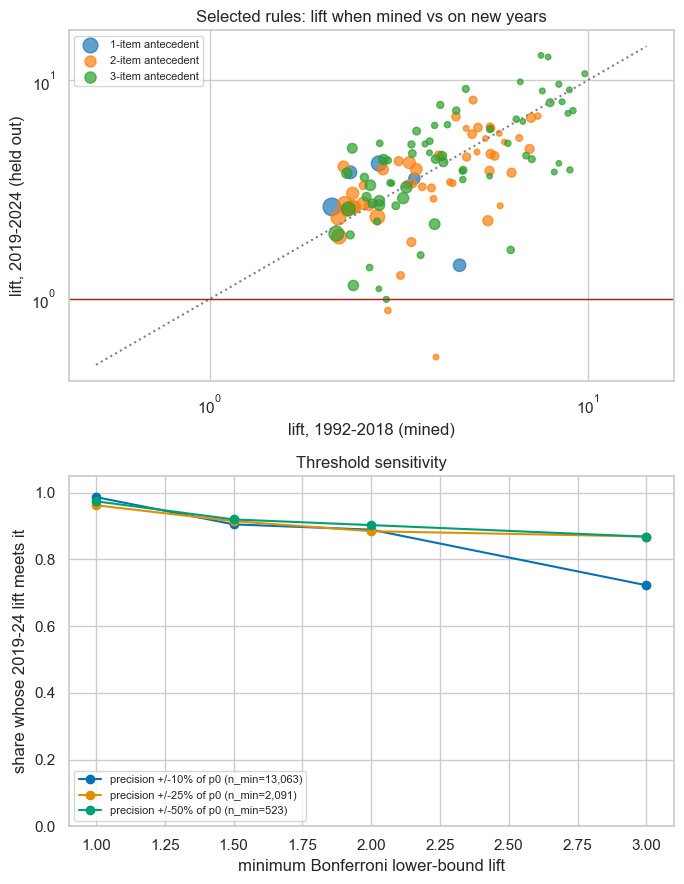

In [21]:
grid_rows = []
for rel in PRECISION_GRID:
    n_min = min_support_count(P0, rel)
    base = candidates(n_min)
    for min_lift in (1.0, 1.5, 2.0, 3.0):
        sel = select_rules(base, min_lift)
        r = replicate(sel)
        grid_rows.append({'relative precision': rel, 'n_min': n_min, 'min lift (lower bound)': min_lift,
                          'rules': len(sel), 'replicate lift > 1': (r['lift_2019'] > 1).mean() if len(r) else np.nan,
                          'replicate lift >= threshold': (r['lift_2019'] >= min_lift).mean() if len(r) else np.nan})
sensitivity = pd.DataFrame(grid_rows)
display(sensitivity.style.format({'n_min': '{:,}', 'replicate lift > 1': '{:.0%}',
                                  'replicate lift >= threshold': '{:.0%}'}).hide(axis='index'))

fig, axes = plt.subplots(2, 1, figsize=(7, 9))  # one report column
colors = {1: 'tab:blue', 2: 'tab:orange', 3: 'tab:green'}
for length, s in selected.groupby('length'):
    axes[0].scatter(s['lift'], s['lift_2019'], s=np.sqrt(s['matches']) / 3, alpha=0.7, color=colors[length],
                    label=f'{length}-item antecedent')
lim = [0.5, max(selected['lift'].max(), selected['lift_2019'].max()) * 1.1]
axes[0].plot(lim, lim, color='gray', ls=':')
axes[0].axhline(1, color='firebrick', lw=1)
axes[0].set(xscale='log', yscale='log', xlabel='lift, 1992-2018 (mined)', ylabel='lift, 2019-2024 (held out)',
            title='Selected rules: lift when mined vs on new years')
axes[0].legend(fontsize=8)
for rel, s in sensitivity.groupby('relative precision'):
    axes[1].plot(s['min lift (lower bound)'], s['replicate lift >= threshold'], marker='o',
                 label=f'precision +/-{rel:.0%} of p0 (n_min={s.n_min.iat[0]:,})')
axes[1].set(xlabel='minimum Bonferroni lower-bound lift', ylabel='share whose 2019-24 lift meets it',
            title='Threshold sensitivity', ylim=(0, 1.05))
axes[1].legend(fontsize=8)
plt.tight_layout()
savefig('association_rules.png')
plt.show()

- **The thresholds are not fragile.** Across the grid, 96-100 % of selected rules keep lift > 1 in 2019-2024, and 87-92 % keep their lift threshold except at the strictest corner (±10 % precision with lift ≥ 3: 72 %, only 18 rules).
- Loosening support to ±50 % (n_min = 523) adds 33 rules at the same replication rate, and tightening to ±10 % (n_min = 13,063) leaves only 45. **±25 % with lift ≥ 2 is a middle choice**: enough rules to describe the types, each estimated to within a quarter of the base rate, and 88 % replicate at full strength on new years.

## 10. Summary

**RQ2 answer (preliminary).** The 2,016 under-served cells (12 % of fires, 38 % of acres) fall into **four reproducible types**, chosen by a stability rule fixed in advance (k = 4: 92 % of bootstrap pairs agree with ARI > 0.8; silhouette 0.17, so the groups overlap). Each type points to a different kind of help:

| Type | What defines it | What help fits |
|---|---|---|
| Remote federal wildlands (617 cells) | 30 km to a station, summer lightning (76 %), 21 of the 100 largest fires, large-fire rate rising to 9.2 % in 2019-24 | detection, aviation and pre-positioned federal initial attack, not new structural stations |
| Federal forests, partial coverage (788) | 15 km, summer lightning, a quarter of all complex fires, low large-fire rate (4.9 %) | federal crews already contain most fires; the risk is the private in-holdings (rule lift 2.4) |
| Private-land spring fires (414) | 15 km, non-federal spring grass and range fires, reported by state and local agencies (83 %), highest large-fire rate in the fit years (9.9 %) | rural and volunteer stations, burn restrictions and prevention in the Plains |
| Tribal lands (197) | busiest cells, 20 km from stations, low large-fire rate | tribal and BIA fire programmes; not a station-placement problem |

**Validation.** The types separate held-out cause (η² = 0.46), reporting agency (η² = 0.60) and region (V = 0.43). They persist into 2019-2024 (κ = 0.78), and K-Means on principal components gives the same partition (ARI 0.98). Density-based and mixture models find no better structure.

**Association rules.** 121 rules with thresholds derived from a precision target and a Bonferroni bound; 98 % keep lift > 1 on 2019-2024. The strongest rules combine distance of 20+ km, private or unknown land and the Plains or sparse cells, with lifts of 8-10.

**Limitations.**
1. Sparse cells (fewer than 30 fires) are excluded from the typology but hold 26 of the 100 largest fires. A separate look at them is the most important extension.
2. The station layer is a recent snapshot of mostly structural stations; federal wildland crews are missing, which overstates the gap on federal land (Milestone 1).
3. Silhouettes of 0.09-0.27 mean the types are regimes with fuzzy borders, not discrete classes.
4. Owner and discovery-time fields are partly administrative, so some of what separates the types is *how* fires are reported, not only how they behave.

**Next steps (optimisation phase).** Repeat the selection for 15 / 25 / 40 km grids and 5-15 km under-served cut-offs; try fuzzy memberships for border cells; build a separate typology for sparse cells from fire-level features; add the cell type as a feature in the RQ1 model.